# SCS 3546 Assignment 2: Transfer Learning with VGG16

**Miguel Morales**  
Student number: [ ]

## Introduction

## Setup

In [1]:
import os
import sys

# Hide TensorFlow's info and warning logs. This must be set before importing tensorflow.
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import numpy as np
import sklearn
import tensorflow as tf
import keras

# Without this, recent ipykernel versions show figures as text instead of images.
%matplotlib inline

# Colab always has the google.colab module loaded.
IN_COLAB = "google.colab" in sys.modules

print(f"Running in Colab: {IN_COLAB}")
print(f"Python:       {sys.version.split()[0]}")
print(f"TensorFlow:   {tf.__version__}")
print(f"Keras:        {keras.__version__}")
print(f"scikit-learn: {sklearn.__version__}")
print(f"NumPy:        {np.__version__}")

# This assignment uses the Keras 3 API, so stop early if an older Keras is loaded.
assert keras.__version__.startswith("3."), f"Keras 3.x is required, found {keras.__version__}"

# Find the GPUs and let each one grow its memory use as needed instead of grabbing it all.
gpus = tf.config.list_physical_devices("GPU")
if gpus:
    for gpu in gpus:
        tf.config.experimental.set_memory_growth(gpu, True)
    print(f"GPUs found ({len(gpus)}): {[gpu.name for gpu in gpus]}")
else:
    print(
        "WARNING: No GPU found. Training will run on the CPU and be very slow. "
        "In Colab, choose Runtime > Change runtime type > GPU. "
        "In WSL2, check that the NVIDIA driver is installed and that nvidia-smi works."
    )

SEED = 42


def set_global_seed(seed=SEED):
    """Seed Python, NumPy and TensorFlow so runs are repeatable."""
    keras.utils.set_random_seed(seed)

set_global_seed()


2026-11-15 20:28:24.133960: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:479] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-11-15 20:28:24.162871: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:10575] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-11-15 20:28:24.162919: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1442] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


Running in Colab: False
Python:       3.12.16
TensorFlow:   2.16.2
Keras:        3.15.1
scikit-learn: 1.5.1
NumPy:        1.26.4
GPUs found (1): ['/physical_device:GPU:0']


## Helper Functions

In [2]:
from pathlib import Path

FLOWERS_URL = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"


def load_dataset(url=FLOWERS_URL):
    """Download flower_photos (cached after the first run) and list its images.

    Returns:
        paths: list of image file paths (str), sorted so the order is the same on every machine
        labels: NumPy int32 array; each value is an index into class_names
        class_names: class folder names, sorted alphabetically
    """
    # Keras caches the download under ~/.keras/datasets, both locally and in Colab.
    extract_dir = Path(keras.utils.get_file("flower_photos", origin=url, extract=True))

    # Newer Keras returns the extraction folder, which contains another flower_photos/ folder;
    # older Keras 3 versions return the image folder directly.
    data_dir = extract_dir / "flower_photos"
    if not data_dir.is_dir():
        data_dir = extract_dir

    class_names = sorted(d.name for d in data_dir.iterdir() if d.is_dir())

    paths, labels = [], []
    for label, class_name in enumerate(class_names):
        # Keep only .jpg images; anything else in the folder (e.g. LICENSE.txt) is skipped.
        class_paths = sorted(p for p in (data_dir / class_name).iterdir() if p.suffix.lower() == ".jpg")
        paths.extend(str(p) for p in class_paths)
        labels.extend([label] * len(class_paths))

    return paths, np.array(labels, dtype=np.int32), class_names

In [3]:
from sklearn.model_selection import train_test_split


def make_split(paths, labels, test_size=0.2, val_fraction=0.15, seed=SEED):
    """Two-stage stratified split: train/test first, then validation carved out of train.

    val_fraction is a share of the training set, not of the whole dataset (D02).
    Stratifying both times keeps the class proportions the same in every split.

    Returns:
        dict with keys "train", "val", "test"; each value is a (paths, labels) tuple
    """
    train_paths, test_paths, train_labels, test_labels = train_test_split(
        paths, labels, test_size=test_size, stratify=labels, random_state=seed
    )
    train_paths, val_paths, train_labels, val_labels = train_test_split(
        train_paths, train_labels, test_size=val_fraction, stratify=train_labels, random_state=seed
    )
    return {
        "train": (train_paths, train_labels),
        "val": (val_paths, val_labels),
        "test": (test_paths, test_labels),
    }

In [4]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32


def load_image(path, resize_mode="stretch"):
    """Read one JPEG and resize it to IMG_SIZE; pixels stay float32 in 0-255."""
    image = tf.io.decode_jpeg(tf.io.read_file(path), channels=3)
    if resize_mode == "stretch":
        # D01: stretch to 224x224 and ignore the original aspect ratio.
        image = tf.image.resize(image, IMG_SIZE)
    else:
        raise ValueError(f"Unknown resize_mode: {resize_mode!r}")
    return tf.cast(image, tf.float32)


def make_tf_dataset(paths, labels, batch_size=BATCH_SIZE, shuffle=False, resize_mode="stretch", seed=SEED):
    """Build a tf.data pipeline: decode -> resize -> float32 (0-255) -> batch -> prefetch.

    No preprocess_input here: the model applies it itself (M01).
    Use shuffle=True for the training split only; keep it False for val/test and feature caching (M03).
    """
    ds = tf.data.Dataset.from_tensor_slices((list(paths), np.asarray(labels, dtype=np.int32)))
    if shuffle:
        # Shuffling file paths (not images) lets the buffer hold the whole split cheaply.
        ds = ds.shuffle(len(paths), seed=seed, reshuffle_each_iteration=True)
    ds = ds.map(lambda p, y: (load_image(p, resize_mode), y), num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)

In [5]:
from keras import layers
from keras.applications import vgg16

INPUT_SHAPE = IMG_SIZE + (3,)


def build_vgg_base():
    """VGG16 convolutional base with ImageNet weights; outputs (None, 7, 7, 512)."""
    return vgg16.VGG16(weights="imagenet", include_top=False, input_shape=INPUT_SHAPE)


def build_augmentation(seed=SEED):
    """Random image changes, applied only when training=True; expects raw 0-255 pixels (M01)."""
    return keras.Sequential(
        [
            layers.RandomFlip("horizontal", seed=seed),
            layers.RandomRotation(0.1, seed=seed),
            layers.RandomZoom(0.1, seed=seed),
            layers.RandomContrast(0.1, seed=seed),
        ],
        name="augmentation",
    )


def build_feature_extractor(base):
    """Raw pixels -> preprocess_input -> VGG16 base, with no augmentation (M03)."""
    inputs = keras.Input(shape=INPUT_SHAPE, name="image")
    x = layers.Lambda(vgg16.preprocess_input, name="vgg16_preprocess")(inputs)
    outputs = base(x, training=False)
    return keras.Model(inputs, outputs, name="feature_extractor")


def extract_features(extractor, ds):
    """Run the extractor over a dataset and return (features, labels) as NumPy arrays.

    ds must not be shuffled, so each feature stays next to its own label (M03).
    """
    features, labels_out = [], []
    for images, batch_labels in ds:
        features.append(extractor.predict_on_batch(images))
        labels_out.append(batch_labels.numpy())
    return np.concatenate(features), np.concatenate(labels_out)

In [6]:
FEATURE_SHAPE = (7, 7, 512)


def build_head(pooling="flatten", units=(256,), dropout=0.0, l2=0.0, batch_norm=False, num_classes=5, name="head"):
    """Classifier head as a standalone keras.Model taking (7, 7, 512) VGG16 features (M02).

    pooling: "flatten" (keeps spatial detail, many weights) or "gap" (global average pooling, few weights)
    units: sizes of the hidden Dense layers, e.g. (256,) or (512, 128); () means no hidden layer
    dropout: dropout rate after each hidden layer (0 = off)
    l2: L2 penalty on the hidden Dense kernels (0 = off)
    batch_norm: add BatchNormalization between each hidden Dense layer and its ReLU
    """
    inputs = keras.Input(shape=FEATURE_SHAPE, name="features")
    if pooling == "flatten":
        x = layers.Flatten(name="flatten")(inputs)
    elif pooling == "gap":
        x = layers.GlobalAveragePooling2D(name="gap")(inputs)
    else:
        raise ValueError(f"Unknown pooling: {pooling!r}")

    regularizer = keras.regularizers.l2(l2) if l2 > 0 else None
    for i, n in enumerate(units, start=1):
        x = layers.Dense(n, kernel_regularizer=regularizer, name=f"dense_{i}")(x)
        if batch_norm:
            x = layers.BatchNormalization(name=f"bn_{i}")(x)
        x = layers.Activation("relu", name=f"relu_{i}")(x)
        if dropout > 0:
            x = layers.Dropout(dropout, name=f"dropout_{i}")(x)

    outputs = layers.Dense(num_classes, activation="softmax", name="predictions")(x)
    return keras.Model(inputs, outputs, name=name)

In [7]:
def build_full_model(base, head, augmentation=None, name="full_model"):
    """Self-contained model on raw 0-255 pixels (M01):
    Input -> [augmentation, training only] -> preprocess_input -> VGG16 base -> head.

    base and head are shared, not copied: weights the head learned on cached features carry over (Q2).
    """
    inputs = keras.Input(shape=INPUT_SHAPE, name="image")
    x = inputs
    if augmentation is not None:
        x = augmentation(x)
    x = layers.Lambda(vgg16.preprocess_input, name="vgg16_preprocess")(x)
    # training=False only affects layers like BatchNorm/Dropout (VGG16 has none); weights still train if unfrozen.
    x = base(x, training=False)
    outputs = head(x)
    return keras.Model(inputs, outputs, name=name)

In [8]:
TRAINABLE_MODES = ("none", "block5", "all")


def set_trainable(base, mode):
    """Choose which VGG16 layers can learn (M06). The caller must recompile the model afterwards.

    "none": freeze every layer (Model 1)
    "block5": train only block5_* layers (Model 2)
    "all": train every layer (Model 3)
    """
    if mode not in TRAINABLE_MODES:
        raise ValueError(f"Unknown mode: {mode!r}; use one of {TRAINABLE_MODES}")
    # Unfreeze the container first, otherwise per-layer flags below are silently ignored.
    base.trainable = True
    for layer in base.layers:
        layer.trainable = mode == "all" or (mode == "block5" and layer.name.startswith("block5_"))


def count_params(model):
    """Return trainable / non-trainable / total parameter counts for the Phase 6 table."""
    trainable = sum(int(np.prod(w.shape)) for w in model.trainable_weights)
    non_trainable = sum(int(np.prod(w.shape)) for w in model.non_trainable_weights)
    return {"trainable": trainable, "non_trainable": non_trainable, "total": trainable + non_trainable}

In [ ]:
import time

import matplotlib.pyplot as plt


def timed_fit(model, *args, **kwargs):
    """Call model.fit(...) and also return the wall-clock training time in seconds (Phase 6 table)."""
    start = time.perf_counter()
    history = model.fit(*args, **kwargs)
    return history, time.perf_counter() - start


def plot_history(history, title=None, loss_ylim=None, acc_ylim=(0.0, 1.0)):
    """Plot loss and accuracy, train vs. validation, side by side.

    Fixed y-limits keep the plots comparable across experiments; pass loss_ylim, e.g. (0, 2), to fix the loss axis too.
    history: a keras History object or its .history dict. The epoch labels on the x-axis are kept as integers (1, 2, 3, ...).
    """
    h = history.history if hasattr(history, "history") else history
    epochs = np.arange(1, len(h["loss"]) + 1)

    fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(12, 4))
    for ax, metric, ylim in [(ax_loss, "loss", loss_ylim), (ax_acc, "accuracy", acc_ylim)]:
        ax.plot(epochs, h[metric], "o-", label="train")
        if f"val_{metric}" in h:
            ax.plot(epochs, h[f"val_{metric}"], "o-", label="validation")

        ax.set_xlabel("epoch")
        ax.set_ylabel(metric)
        ax.set_xticks(epochs)
        ax.set_xticklabels([str(int(e)) for e in epochs])
        if ylim is not None:
            ax.set_ylim(ylim)
        ax.grid(alpha=0.3)
        ax.legend()

    if title:
        fig.suptitle(title)
    fig.tight_layout()
    plt.show()

### Helper check on a small subset

A quick end-to-end run of the helpers on about 200 images before any full training.

***Note: the helpers are checked on a subset first to ensure they work correctly before running on the full dataset. This helps catch any issues early and saves time during full training.***

split       daisy  dandelion      roses sunflowers     tulips   total
train         430        611        436        475        543    2495
val            76        108         77         84         96     441
test          127        179        128        140        160     734

subset train [28 39 28 30 35] | subset val [ 7 10  7  7  9]

one batch: (32, 224, 224, 3) <dtype: 'float32'> | min=0.0 max=255.0
feature extractor output: (32, 7, 7, 512)

none    trainable: base          0 + head 132,613 =    132,613
block5  trainable: base  7,079,424 + head 132,613 =  7,212,037
all     trainable: base 14,714,688 + head 132,613 = 14,847,301

cached features: train (160, 7, 7, 512), val (40, 7, 7, 512)
Epoch 1/5
5/5 - 1s - 295ms/step - accuracy: 0.2688 - loss: 4.8379 - val_accuracy: 0.5000 - val_loss: 1.8585
Epoch 2/5
5/5 - 0s - 14ms/step - accuracy: 0.7437 - loss: 0.7495 - val_accuracy: 0.6500 - val_loss: 1.4178
Epoch 3/5
5/5 - 0s - 15ms/step - accuracy: 0.9062 - loss: 0.2908 - val_accuracy: 

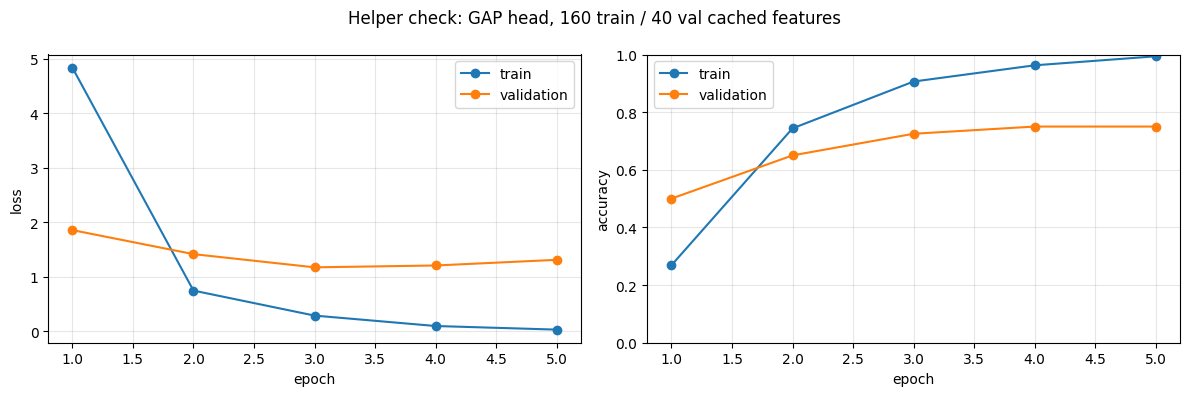

In [12]:
set_global_seed()

# 1. Full split; the test set is only counted here, never used for training or tuning (Q1).
paths, labels, class_names = load_dataset()
splits = make_split(paths, labels)
print(f"{'split':6s}" + "".join(f"{c:>11s}" for c in class_names) + f"{'total':>8s}")
for split_name, (_, split_labels) in splits.items():
    counts = np.bincount(split_labels, minlength=len(class_names))
    print(f"{split_name:6s}" + "".join(f"{n:11d}" for n in counts) + f"{counts.sum():8d}")

# 2. Small stratified subset: 160 train + 40 validation images.
sub_train_paths, _, sub_train_labels, _ = train_test_split(
    *splits["train"], train_size=160, stratify=splits["train"][1], random_state=SEED
)
sub_val_paths, _, sub_val_labels, _ = train_test_split(
    *splits["val"], train_size=40, stratify=splits["val"][1], random_state=SEED
)
print(f"\nsubset train {np.bincount(sub_train_labels)} | subset val {np.bincount(sub_val_labels)}")

# 3. One batch of raw pixels: no preprocess_input in the pipeline (M01).
images, _ = next(iter(make_tf_dataset(sub_train_paths, sub_train_labels, shuffle=True)))
pixels = images.numpy()
print(f"\none batch: {images.shape} {images.dtype} | min={pixels.min():.1f} max={pixels.max():.1f}")
assert images.shape == (BATCH_SIZE, *INPUT_SHAPE)
assert pixels.min() >= 0 and 1 < pixels.max() <= 255, "expected raw 0-255 pixels (M01)"

# 4. Feature extractor on that batch.
base = build_vgg_base()
extractor = build_feature_extractor(base)
batch_features = extractor.predict_on_batch(images)
print(f"feature extractor output: {batch_features.shape}")
assert batch_features.shape == (BATCH_SIZE, *FEATURE_SHAPE)

# 5. Trainable parameters per fine-tuning mode (M06); counts must match VGG16's known layer sizes.
head = build_head(pooling="gap")
full = build_full_model(base, head)
head_params = count_params(head)["trainable"]
expected_base = {"none": 0, "block5": 7_079_424, "all": 14_714_688}
print()
for mode, expected in expected_base.items():
    set_trainable(base, mode)
    base_trainable = count_params(base)["trainable"]
    print(f"{mode:7s} trainable: base {base_trainable:>10,} + head {head_params:,} = {count_params(full)['trainable']:>10,}")
    assert base_trainable == expected
set_trainable(base, "none")

# 6. Cache subset features (no shuffling, M03), then train the head on them for 5 epochs.
train_features, train_y = extract_features(extractor, make_tf_dataset(sub_train_paths, sub_train_labels))
val_features, val_y = extract_features(extractor, make_tf_dataset(sub_val_paths, sub_val_labels))
print(f"\ncached features: train {train_features.shape}, val {val_features.shape}")
assert np.array_equal(train_y, sub_train_labels) and np.array_equal(val_y, sub_val_labels)

head.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
history, seconds = timed_fit(
    head, train_features, train_y, validation_data=(val_features, val_y),
    epochs=5, batch_size=BATCH_SIZE, verbose=2,
)
print(f"head training time: {seconds:.1f}s")
plot_history(history, title="Helper check: GAP head, 160 train / 40 val cached features")

## 1. Data Preparation

## 2. Model 1: Frozen VGG16 (experiments + final model)

## 3. Model 2: Unfreeze block5

## 4. Model 3: Unfreeze all layers

## 5. Final Evaluation on the Test Set

## 6. Model Comparison

## 7. Conclusions and Limitations